# 03 - Model Training and Hyperparameter Search

The full search (six models, 199 candidate configurations, 5-fold CV) is
executed by `python -m src.train` and takes several minutes. This notebook
demonstrates the identical code path on a reduced search so it runs quickly, then
reports the full saved results.

In [1]:
import os, sys, pathlib
root = pathlib.Path.cwd()
while not (root / "src" / "config.py").exists():
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)          # relative paths in the notebooks resolve from the root
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 160)
print("project root:", root)

project root: /home/shreyas/projects/dry-bean-classification


## 1. A live, reduced search

In [2]:
from src.preprocessing import load_split
from src.preprocessing import build_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import time
split = load_split()
pipe = build_pipeline(LogisticRegression(max_iter=3000, random_state=42), scale=True)
grid = GridSearchCV(pipe, {"model__C": [0.1, 1.0, 10.0]}, scoring="f1_macro",
                    cv=StratifiedKFold(2, shuffle=True, random_state=42), n_jobs=-1)
t0 = time.perf_counter(); grid.fit(split.X_train, split.y_train)
print(f"best C = {grid.best_params_['model__C']}, "
      f"CV macro F1 = {grid.best_score_:.4f} ({time.perf_counter()-t0:.1f}s)")

best C = 10.0, CV macro F1 = 0.9361 (1.4s)


## 2. Full cross-validation results

In [3]:
cv = pd.read_csv("results/metrics/cv_summary.csv")
cv[["label", "search", "n_candidates", "cv_macro_f1_mean", "cv_macro_f1_std",
    "search_time_s"]].sort_values("cv_macro_f1_mean", ascending=False)

,label,search,n_candidates,cv_macro_f1_mean,cv_macro_f1_std,search_time_s
0,RBF-SVM,grid,16,0.94440,0.00557,7.43
1,Hist Gradient Boosting,random,20,0.94236,0.00491,71.57
2,K-Nearest Neighbours,grid,40,0.93820,0.00479,4.07
3,Random Forest,random,25,0.93750,0.00367,183.95
4,Logistic Regression,grid,5,0.93740,0.00481,2.72
5,Extra Trees,random,25,0.93440,0.00334,24.38


In [4]:
import json
for _, row in cv.iterrows():
    print(f"{row['label']:<26} {row['best_params']}")

RBF-SVM                    {"C": 100.0, "gamma": 0.01}
Hist Gradient Boosting     {"min_samples_leaf": 20, "max_leaf_nodes": 63, "max_iter": 400, "learning_rate": 0.1, "l2_regularization": 1.0}
K-Nearest Neighbours       {"metric": "euclidean", "n_neighbors": 9, "weights": "distance"}
Random Forest              {"min_samples_split": 10, "min_samples_leaf": 2, "max_features": 0.5, "max_depth": 30}
Logistic Regression        {"C": 100.0}
Extra Trees                {"min_samples_split": 10, "min_samples_leaf": 2, "max_features": 0.5, "max_depth": 30}


## 3. RBF-SVM (C, gamma) surface

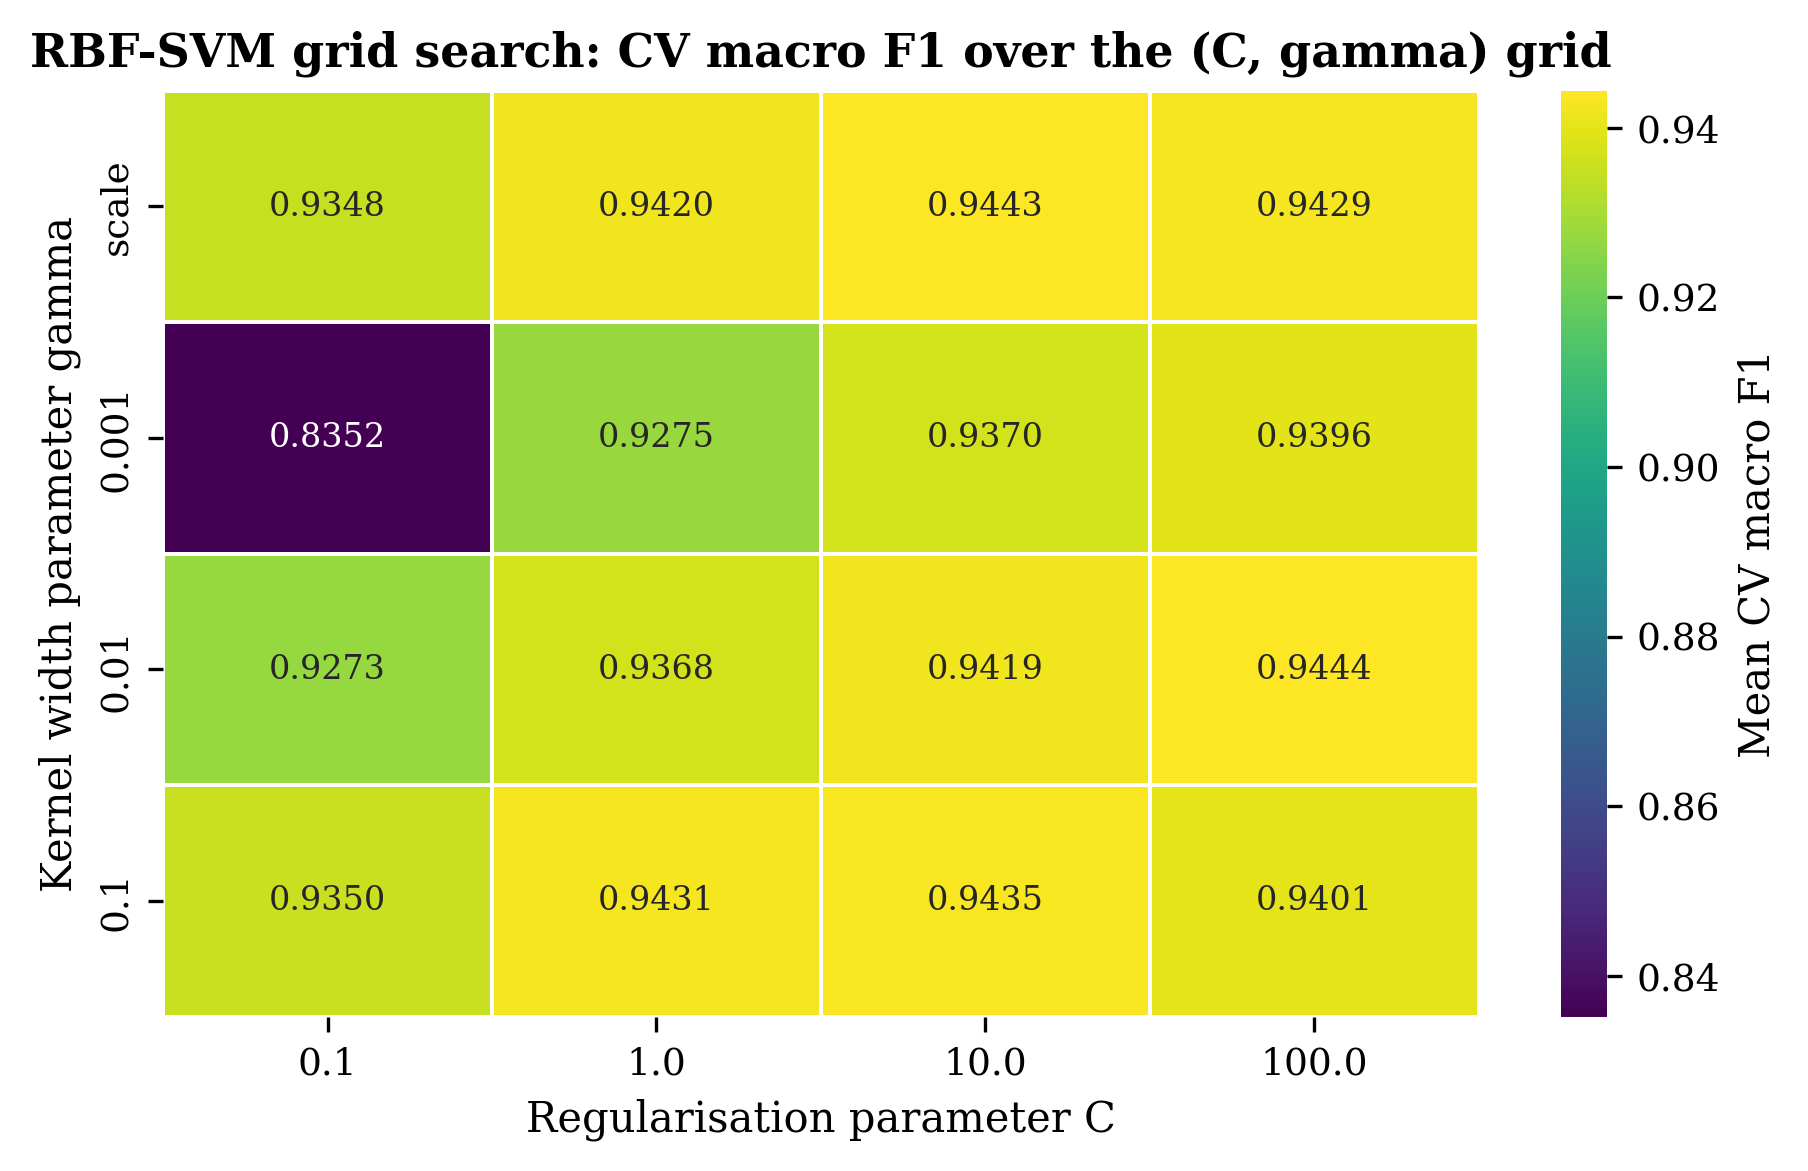

In [5]:
from src.evaluate import fig_svm_heatmap
fig_svm_heatmap()
from IPython.display import Image, display
display(Image("figures/models/fig_5_2_svm_grid_search.png", width=560))

The surface is flat between C = 1 and C = 100: once the margin penalty is
large enough, additional capacity buys nothing because the classes are already
almost separable in the induced feature space. Very small C (0.1) underfits and
large gamma (0.1) overfits, which is the expected bias-variance behaviour.

## 4. Model selection

In [6]:
meta = json.loads(open("results/experiment_metadata.json").read())
print("selected:", meta["best_model_label"])
print("CV macro F1:", meta["cv_macro_f1_mean"], "+/-", meta["cv_macro_f1_std"])
print("best params:", meta["best_params"])

selected: RBF-SVM
CV macro F1: 0.9444 +/- 0.00557
best params: {'C': 100.0, 'gamma': 0.01}


## 5. Feature ablation and class weighting

In [7]:
pd.read_csv("results/metrics/feature_ablation.csv")

,feature_set,n_features,cv_macro_f1_mean,cv_macro_f1_std
0,all_16_features,16,0.93621,0.00306
1,11_features_reduced,11,0.93724,0.00287


In [8]:
pd.read_csv("results/metrics/class_weight_experiment.csv")

,model,class_weight,cv_macro_f1_mean,cv_macro_f1_std
0,RBF-SVM,none,0.94204,0.00522
1,RBF-SVM,balanced,0.94068,0.00521


Removing the five redundant size features costs a small but measurable
amount of macro F1, and balancing the class weights does not improve macro F1 for
the selected model. The original class distribution was therefore kept.